# Industry Risk & Return Analysis

## 01. Project Overview

A reusable framework that generalizes single-company
*Risk & Return Analysis* into a **multi-company
peer-comparison** tool. Pick an industry, list ~6 tickers in `src/config.py`,
and this notebook produces the rigorous return/risk/market-relationship
analysis — for all of them at once, side by side.

This is a **historical, descriptive** study. Results characterize observed
behavior during the sample period and are **not** a forecast of future
returns, and nothing here is investment advice.

**Framework:** Company Selection → Data Acquisition → Validation → Monthly
Returns → Metric Engine → Peer Comparison → Visualizations → Company
Profiles → Findings


## 02. Research Questions

1. Which companies generated the highest historical compounded returns?
2. Which companies showed the lowest historical volatility?
3. Which companies experienced the smallest historical maximum drawdowns?
4. Which companies had the strongest historical risk-adjusted performance?
5. Which companies were most sensitive to the benchmark?
6. Which companies were least correlated with the benchmark?
7. How similar were the companies to each other?
8. Did companies with higher historical returns also exhibit higher historical risk?
9. Which companies showed unusual skewness or kurtosis?
10. What trade-offs become visible when return and risk are considered together?

Answers appear in Section 19, generated only after the calculations below have run.


## 03. Configuration

Single source of truth for the company universe, benchmark, date range, and frequency. See `src/config.py`.

In [15]:
import sys
sys.path.insert(0, "..")  # so `src` is importable from notebooks/

from src import config as cfg
from src import data_loader as dl
from src import preprocessing as prep
from src import metrics as m
from src import comparison as comp
from src import visualization as viz

cfg.validate_config()

Configuration validated successfully.

Industry     : IT Services
Companies    : 6 configured
  - TCS          -> TCS.NS
  - Infosys      -> INFY.NS
  - Wipro        -> WIPRO.NS
  - HCL Technologies -> HCLTECH.NS
  - Tech Mahindra -> TECHM.NS
  - Mphasis      -> MPHASIS.NS
Benchmark    : NIFTY 50 (^NSEI)
Period       : 2011-01-01 to 2025-12-31
Interval     : 1mo  (12 periods/year)

Directories ready:
  - D:\industry-risk-return-analysis\data\raw
  - D:\industry-risk-return-analysis\data\processed
  - D:\industry-risk-return-analysis\figures
  - D:\industry-risk-return-analysis\outputs


True

## 04. Company Universe

The companies configured for this run (edit `src/config.py` to change industry/companies).

In [16]:
import pandas as pd

universe_table = pd.DataFrame({
    "Ticker": {**cfg.COMPANIES, cfg.BENCHMARK_NAME: cfg.BENCHMARK}
}).rename_axis("Name")
universe_table

,Ticker
Name,
TCS,TCS.NS
Infosys,INFY.NS
Wipro,WIPRO.NS
HCL Technologies,HCLTECH.NS
Tech Mahindra,TECHM.NS
Mphasis,MPHASIS.NS
NIFTY 50,^NSEI


## 05. Data Acquisition

Downloads every company + the benchmark with **identical** settings
(same dates, interval, `auto_adjust`), saves raw CSVs to `data/raw/`, and
reloads them with the header fix `load_price_csv()` applies (the same
"Price" → "Date", skip-first-two-rows fix the original notebook used —
see `src/data_loader.py` for why yfinance's saved CSVs need it).

**Requires internet access to Yahoo Finance.** If this cell fails in a
sandboxed environment, run the notebook locally.


In [17]:
price_data = dl.download_all(
    companies=cfg.COMPANIES,
    benchmark=cfg.BENCHMARK,
    benchmark_name=cfg.BENCHMARK_NAME,
    start=cfg.START_DATE,
    end=cfg.END_DATE,
    interval=cfg.INTERVAL,
    auto_adjust=cfg.AUTO_ADJUST,
    raw_dir=cfg.RAW_DIR,
)
print(f"Downloaded {len(price_data)} series: {list(price_data.keys())}")

Downloaded 7 series: ['TCS', 'Infosys', 'Wipro', 'HCL Technologies', 'Tech Mahindra', 'Mphasis', 'NIFTY 50']


## 06. Data Quality Checks

Same checks as the original Reliance notebook, run across every company + the benchmark.

In [18]:
quality_summary = prep.data_quality_summary(price_data)
quality_summary

,Start,End,Observations,Missing,Status,Issues
Company,,,,,,
HCL Technologies,2011-01-01,2025-12-01,180,0,OK,
Infosys,2011-01-01,2025-12-01,180,0,OK,
Mphasis,2011-01-01,2025-12-01,180,0,OK,
NIFTY 50,2011-01-01,2025-12-01,180,0,OK,
TCS,2011-01-01,2025-12-01,180,0,OK,
Tech Mahindra,2011-01-01,2025-12-01,180,0,OK,
Wipro,2011-01-01,2025-12-01,180,0,OK,


In [19]:
# Flag (don't silently drop) any company with materially less history than the others
expected_obs = len(price_data[cfg.BENCHMARK_NAME])
short_history = prep.flag_insufficient_history(quality_summary, min_observations=int(expected_obs * 0.9))
if short_history:
    print("Flagged for insufficient history — review before including in the comparison:", short_history)
else:
    print("All series have sufficient history.")

All series have sufficient history.


In [20]:
# Large-move flags for manual review (not auto-treated as errors — genuine market
# shocks and corporate actions both produce large moves)
for name, df in price_data.items():
    flagged = prep.check_corporate_action_discontinuities(df)
    if len(flagged):
        print(f"{name}: {len(flagged)} month(s) with |move| > 35% — review manually")
        print(flagged)

HCL Technologies: 2 month(s) with |move| > 35% — review manually
Date
2011-08-01    2.376746
2011-09-01   -0.751095
Name: Close, dtype: float64
Mphasis: 2 month(s) with |move| > 35% — review manually
Date
2011-02-01   -0.356408
2020-07-01    0.372176
Name: Close, dtype: float64


## 07. Data Preparation

Convert each company's + the benchmark's monthly Close prices into returns, then align onto a common date index so every comparison is apples-to-apples.

In [21]:
returns_all = {name: prep.prepare_monthly_returns(df) for name, df in price_data.items()}
aligned = prep.align_returns(returns_all)

market_returns = aligned[cfg.BENCHMARK_NAME]
company_returns = {name: aligned[name] for name in cfg.COMPANIES}

aligned.head()

,TCS,Infosys,Wipro,HCL Technologies,Tech Mahindra,Mphasis,NIFTY 50
Date,,,,,,,
2011-02-01,-0.042475,-0.038682,0.000228,-0.098421,-0.008757,-0.356408,-0.031357
2011-03-01,0.066337,0.081479,0.095847,0.080235,0.047888,-0.037659,0.093845
2011-04-01,-0.015415,-0.103369,-0.062266,0.094709,0.015159,0.127273,-0.014442
2011-05-01,-0.007292,-0.034573,-0.008661,-0.012280,-0.012529,0.000427,-0.048074
2011-06-01,0.030366,0.044801,-0.055502,-0.038947,0.067055,-0.072176,0.031847


## 08. Return Calculation

$$R_t = \frac{P_t}{P_{t-1}} - 1$$

Applied identically to every company via `prep.prepare_monthly_returns()` —
no per-company duplicated code.


In [22]:
list(company_returns.keys())[:1] and company_returns[list(company_returns.keys())[0]].head()

Date
2011-02-01   -0.042475
2011-03-01    0.066337
2011-04-01   -0.015415
2011-05-01   -0.007292
2011-06-01    0.030366
Name: TCS, dtype: float64

## 09–14. Metrics

Sections 09 (Return), 10 (Risk), 11 (Distribution), 12 (Risk-Adjusted),
13 (Benchmark Analysis), and 14 (Beta & Correlation) are all computed by
one call per company via `metrics.calculate_all_metrics()` — see
`src/metrics.py` for the formulas and the reasoning behind each one
(e.g. why CAGR differs from average return × 12, why volatility and max
drawdown answer different questions, why beta is cross-validated two ways).

`RISK_FREE_RATE` is read from `config.py` rather than assumed inside a
formula — set it there before running Sharpe/Sortino for real (e.g. the
prevailing Indian 10-year G-Sec yield).


In [23]:
RISK_FREE_RATE = cfg.RISK_FREE_RATE  # set a real annualized rate in config.py before relying on Sharpe/Sortino

per_company_metrics = {
    name: m.calculate_all_metrics(r, market_returns, cfg.PERIODS_PER_YEAR, RISK_FREE_RATE)
    for name, r in company_returns.items()
}
pd.DataFrame(per_company_metrics).T.round(4)

,Avg Monthly Return,Cumulative Return,CAGR,Best Month,Best Month Date,Worst Month,Worst Month Date,Monthly Volatility,Annualized Volatility,Max Drawdown,...,Downside Deviation,Skewness,Kurtosis,Covariance,Correlation,Beta (Covariance),Beta (Regression),Sharpe Ratio,Sortino Ratio,Calmar Ratio
TCS,0.013378,6.563933,0.145277,0.239703,2018-04-01 00:00:00,-0.152988,2025-02-01 00:00:00,0.064462,0.223303,-0.34449,...,0.179177,0.471255,0.537855,0.001115,0.371319,0.513884,0.513884,0.415071,0.494093,0.421716
Infosys,0.012813,4.976463,0.127333,0.312589,2020-07-01 00:00:00,-0.226314,2013-04-01 00:00:00,0.074918,0.259522,-0.328813,...,0.251274,0.061382,1.376014,0.001326,0.379987,0.611178,0.611178,0.33101,0.330622,0.38725
Wipro,0.010116,2.763756,0.092922,0.279081,2020-07-01 00:00:00,-0.203134,2013-04-01 00:00:00,0.074077,0.256611,-0.483052,...,0.2302,0.328926,1.322236,0.000973,0.282024,0.448523,0.448523,0.208661,0.225706,0.192364
HCL Technologies,0.029351,17.884977,0.217726,2.376746,2011-08-01 00:00:00,-0.751095,2011-09-01 00:00:00,0.200145,0.693324,-0.764226,...,0.375801,8.819151,108.31093,0.000166,0.017812,0.076535,0.076535,0.410138,0.740227,0.284898
Tech Mahindra,0.018171,13.035605,0.193739,0.264649,2020-07-01 00:00:00,-0.229984,2020-03-01 00:00:00,0.081809,0.283396,-0.447838,...,0.267485,-0.029054,0.37812,0.001598,0.419286,0.736424,0.736424,0.529998,0.541454,0.43261
Mphasis,0.015185,5.450276,0.133113,0.372176,2020-07-01 00:00:00,-0.356408,2011-02-01 00:00:00,0.097807,0.338813,-0.460184,...,0.296702,0.248624,2.233645,0.002017,0.442742,0.929682,0.929682,0.337569,0.381255,0.289262


## 15. Peer Comparison

One master DataFrame — the same table as above, built via the reusable `compare_companies()` engine and saved to `outputs/company_metrics.csv`.

In [24]:
comparison_df = comp.compare_companies(company_returns, market_returns, cfg.PERIODS_PER_YEAR, RISK_FREE_RATE)
comparison_df.to_csv(f"{cfg.OUTPUTS_DIR}/company_metrics.csv")

annual_returns_table = pd.DataFrame({name: m.annual_returns(r) for name, r in company_returns.items()})
annual_returns_table.to_csv(f"{cfg.OUTPUTS_DIR}/annual_returns.csv")

comparison_df.round(4)

,Avg Monthly Return,Cumulative Return,CAGR,Best Month,Best Month Date,Worst Month,Worst Month Date,Monthly Volatility,Annualized Volatility,Max Drawdown,...,Downside Deviation,Skewness,Kurtosis,Covariance,Correlation,Beta (Covariance),Beta (Regression),Sharpe Ratio,Sortino Ratio,Calmar Ratio
TCS,0.013378,6.563933,0.145277,0.239703,2018-04-01 00:00:00,-0.152988,2025-02-01 00:00:00,0.064462,0.223303,-0.34449,...,0.179177,0.471255,0.537855,0.001115,0.371319,0.513884,0.513884,0.415071,0.494093,0.421716
Infosys,0.012813,4.976463,0.127333,0.312589,2020-07-01 00:00:00,-0.226314,2013-04-01 00:00:00,0.074918,0.259522,-0.328813,...,0.251274,0.061382,1.376014,0.001326,0.379987,0.611178,0.611178,0.33101,0.330622,0.38725
Wipro,0.010116,2.763756,0.092922,0.279081,2020-07-01 00:00:00,-0.203134,2013-04-01 00:00:00,0.074077,0.256611,-0.483052,...,0.2302,0.328926,1.322236,0.000973,0.282024,0.448523,0.448523,0.208661,0.225706,0.192364
HCL Technologies,0.029351,17.884977,0.217726,2.376746,2011-08-01 00:00:00,-0.751095,2011-09-01 00:00:00,0.200145,0.693324,-0.764226,...,0.375801,8.819151,108.31093,0.000166,0.017812,0.076535,0.076535,0.410138,0.740227,0.284898
Tech Mahindra,0.018171,13.035605,0.193739,0.264649,2020-07-01 00:00:00,-0.229984,2020-03-01 00:00:00,0.081809,0.283396,-0.447838,...,0.267485,-0.029054,0.37812,0.001598,0.419286,0.736424,0.736424,0.529998,0.541454,0.43261
Mphasis,0.015185,5.450276,0.133113,0.372176,2020-07-01 00:00:00,-0.356408,2011-02-01 00:00:00,0.097807,0.338813,-0.460184,...,0.296702,0.248624,2.233645,0.002017,0.442742,0.929682,0.929682,0.337569,0.381255,0.289262


## 16. Metric Leaders

**No arbitrary overall #1 ranking.** Each metric is reported independently,
with `higher`/`lower`/`descriptive` direction shown explicitly — beta,
correlation, skew, and kurtosis are reported as *characteristics*, never
labeled good or bad.


In [25]:
leaders = comp.identify_metric_leaders(comparison_df)
leaders.to_csv(f"{cfg.OUTPUTS_DIR}/findings.csv", index=False)
leaders

,Metric,Direction,Historical Leader,Value,Note
0,CAGR,higher,HCL Technologies,0.217726,highest
1,Cumulative Return,higher,HCL Technologies,17.884977,highest
2,Avg Monthly Return,higher,HCL Technologies,0.029351,highest
3,Annualized Volatility,lower,TCS,0.223303,lowest
4,Monthly Volatility,lower,TCS,0.064462,lowest
5,Downside Deviation,lower,TCS,0.179177,lowest
6,Max Drawdown,higher,Infosys,-0.328813,highest
7,Sharpe Ratio,higher,Tech Mahindra,0.529998,highest
8,Sortino Ratio,higher,HCL Technologies,0.740227,highest
9,Calmar Ratio,higher,Tech Mahindra,0.432610,highest


## 17. Visual Analysis

All ten charts from the spec, saved to `figures/`.

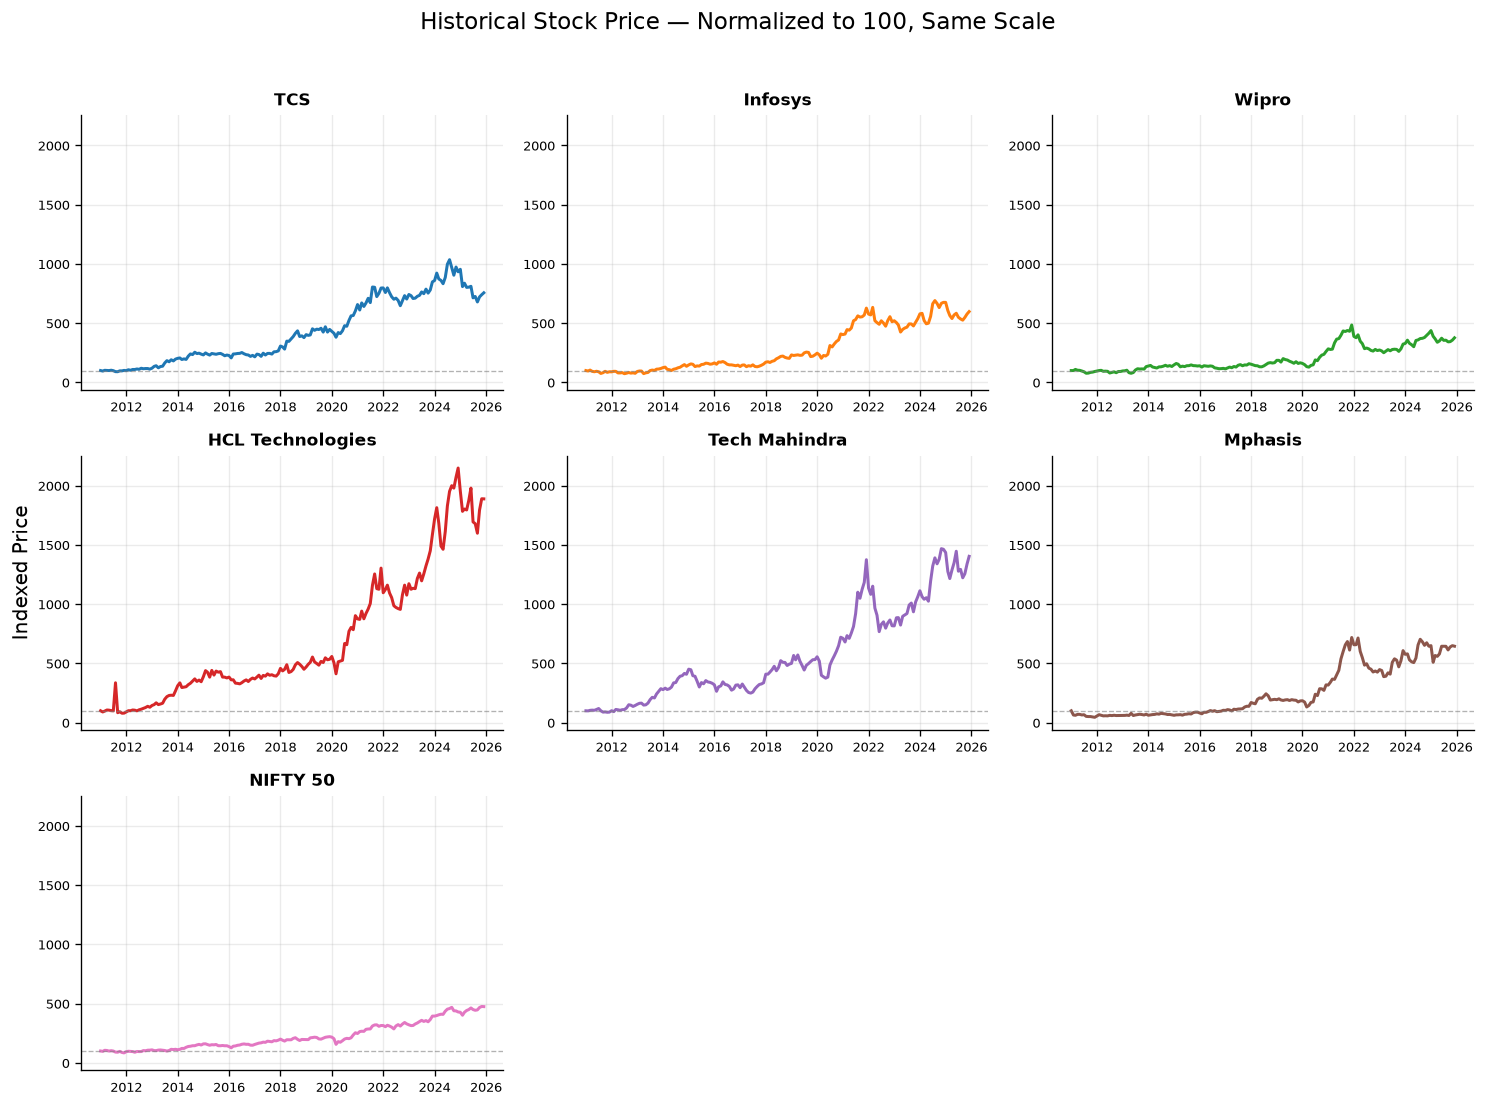

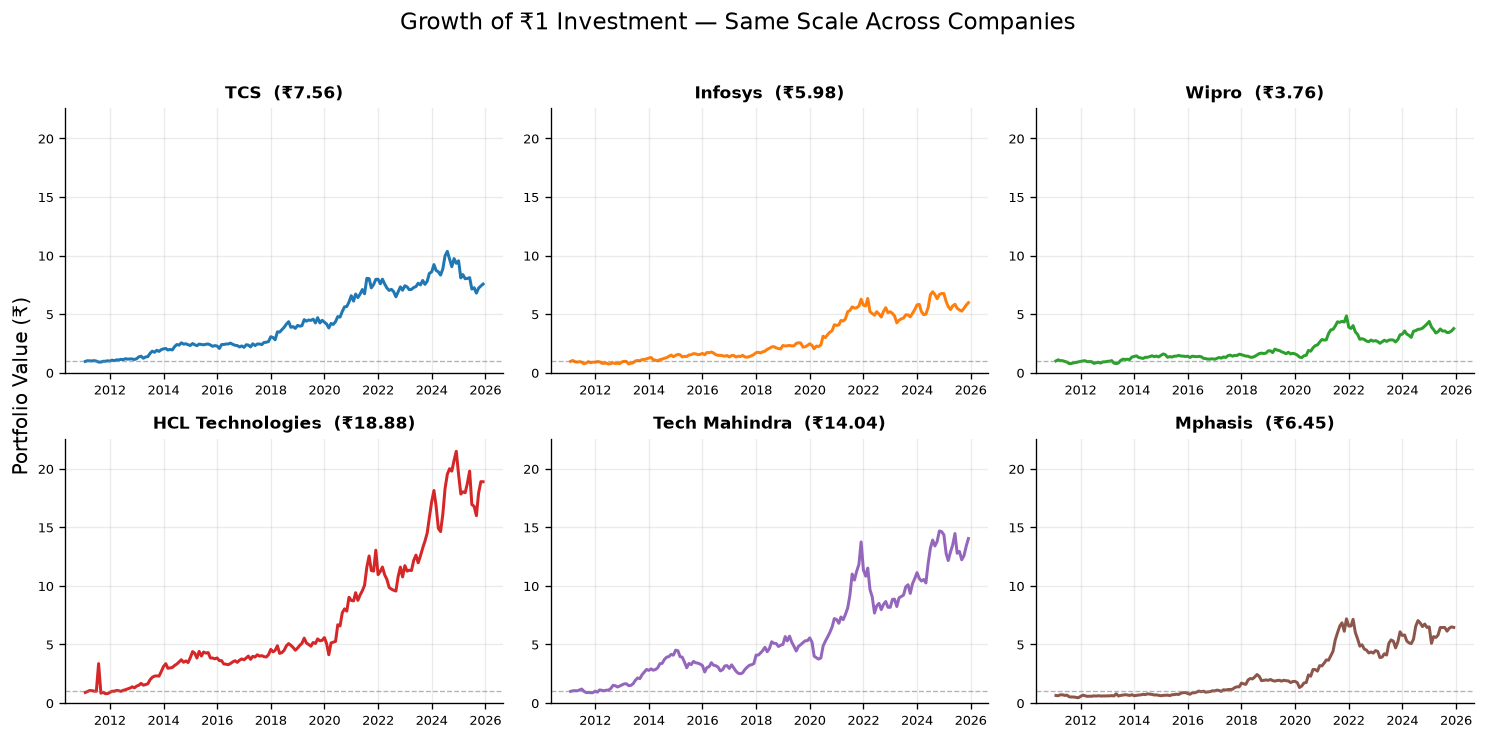

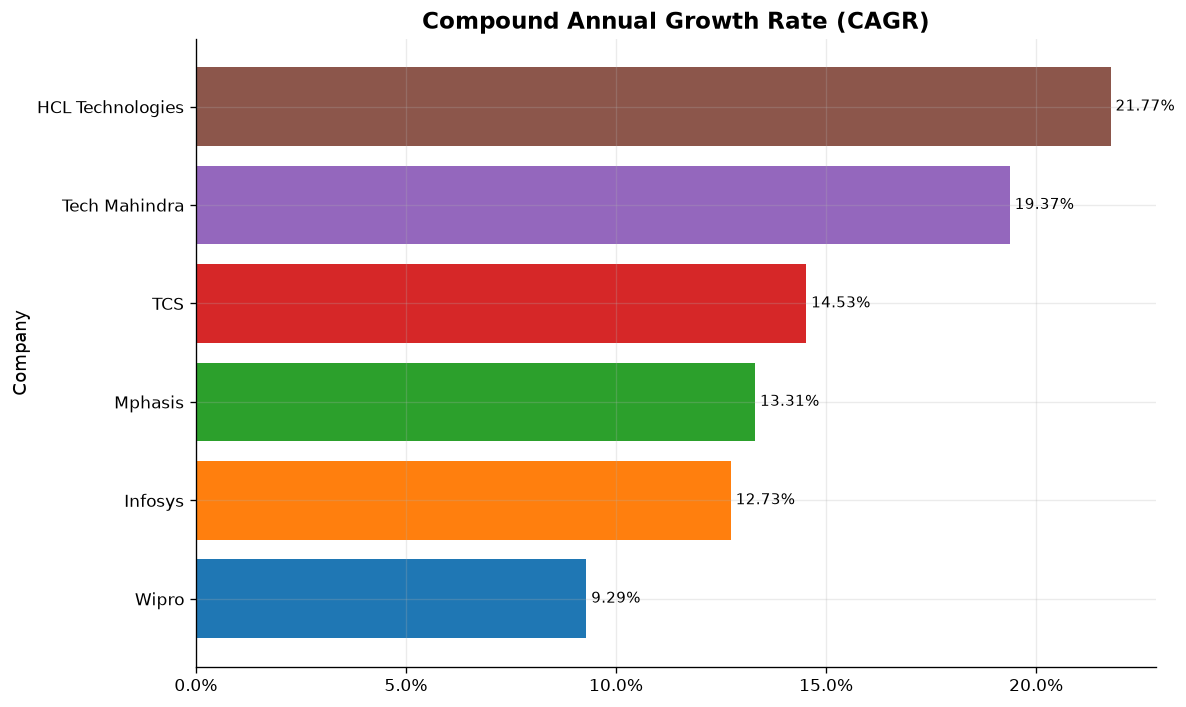

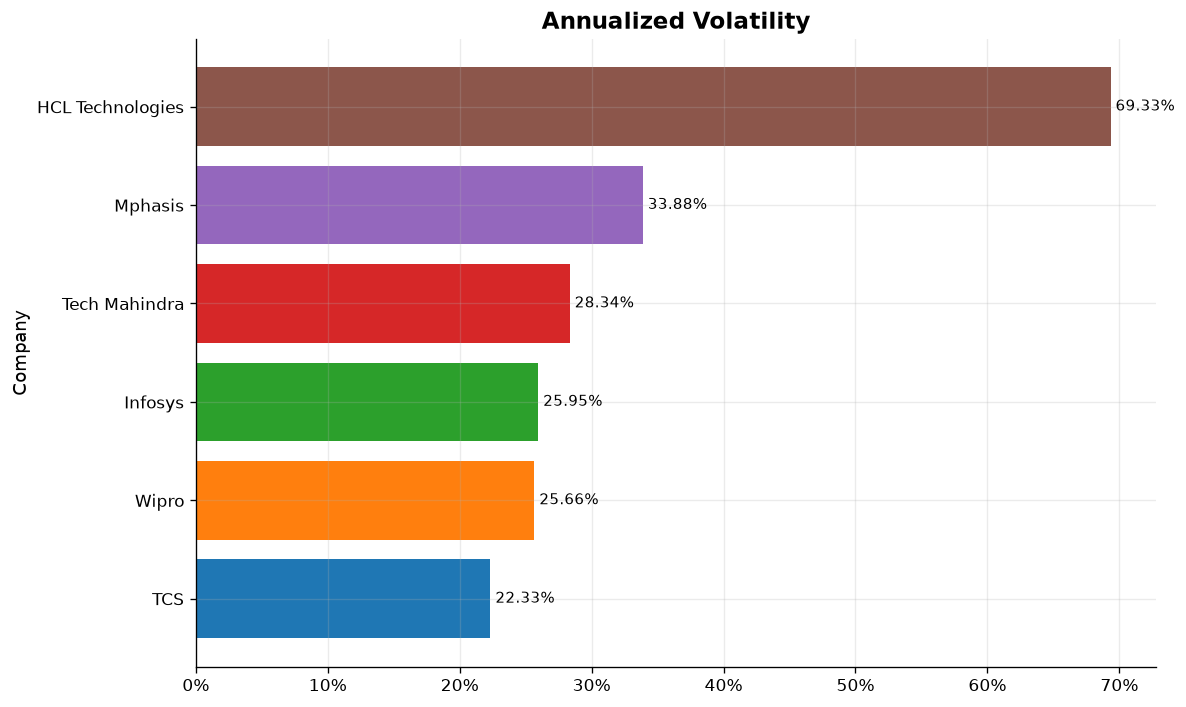

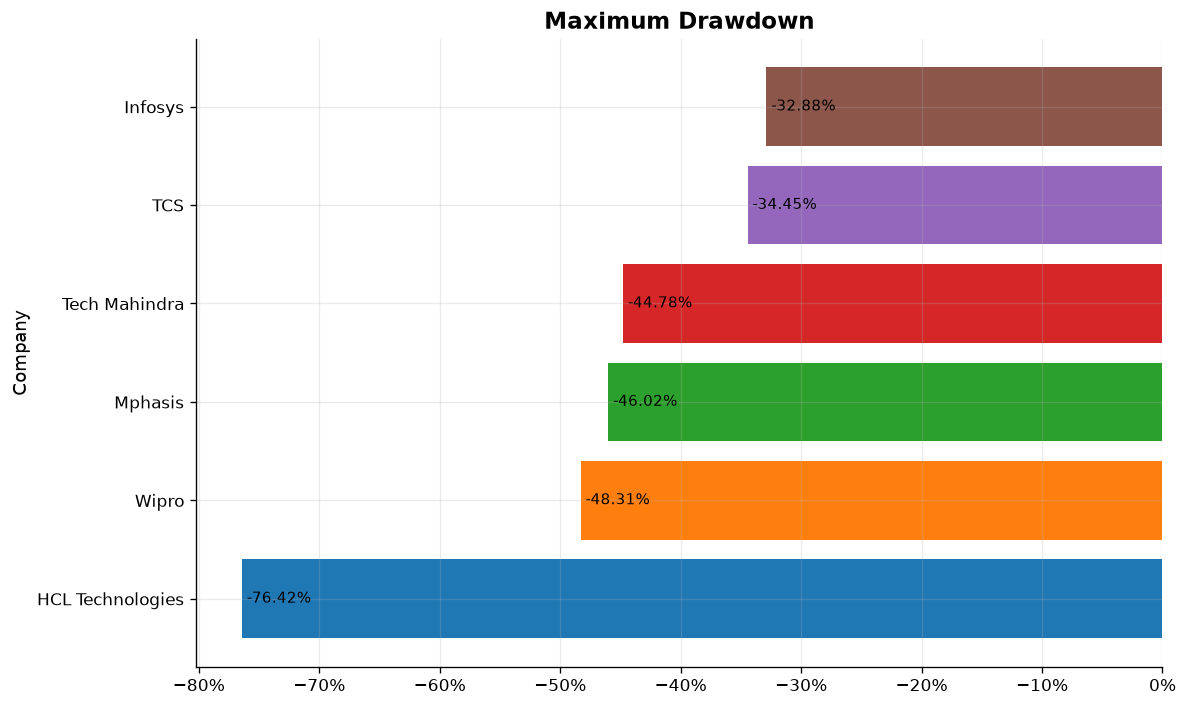

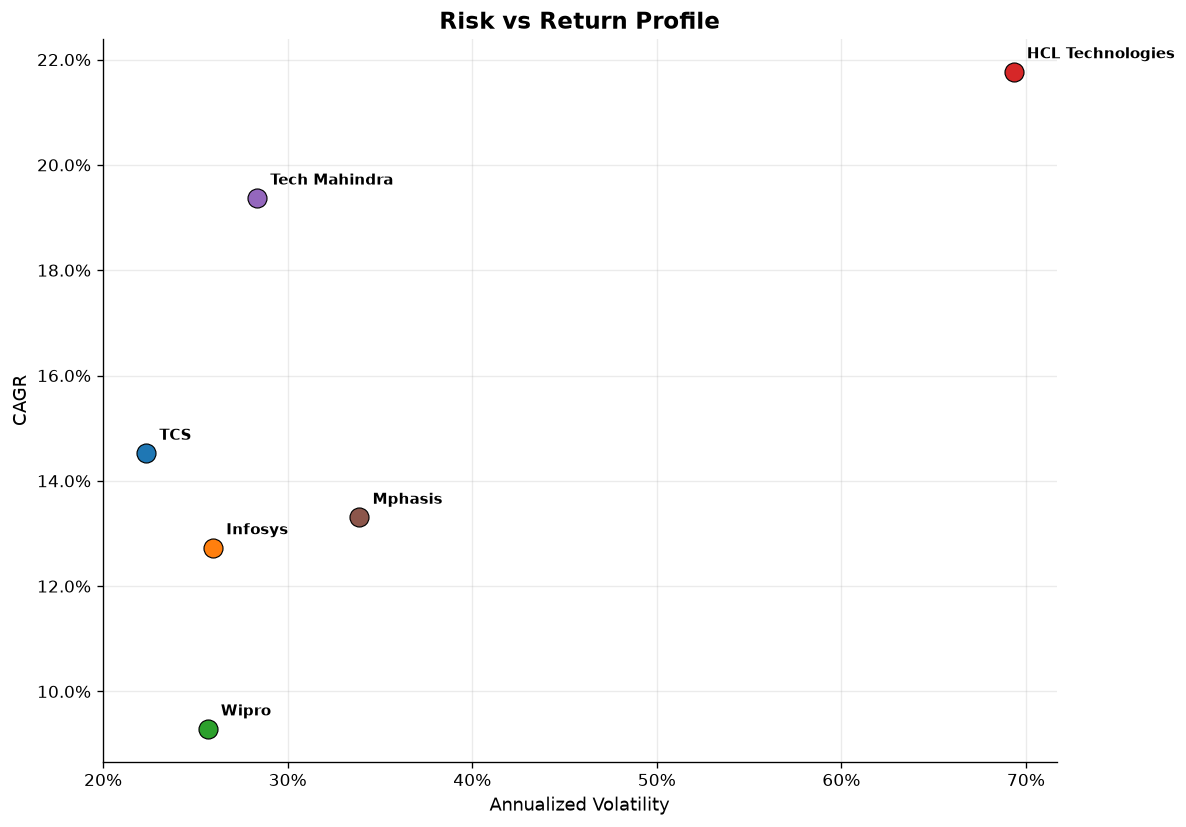

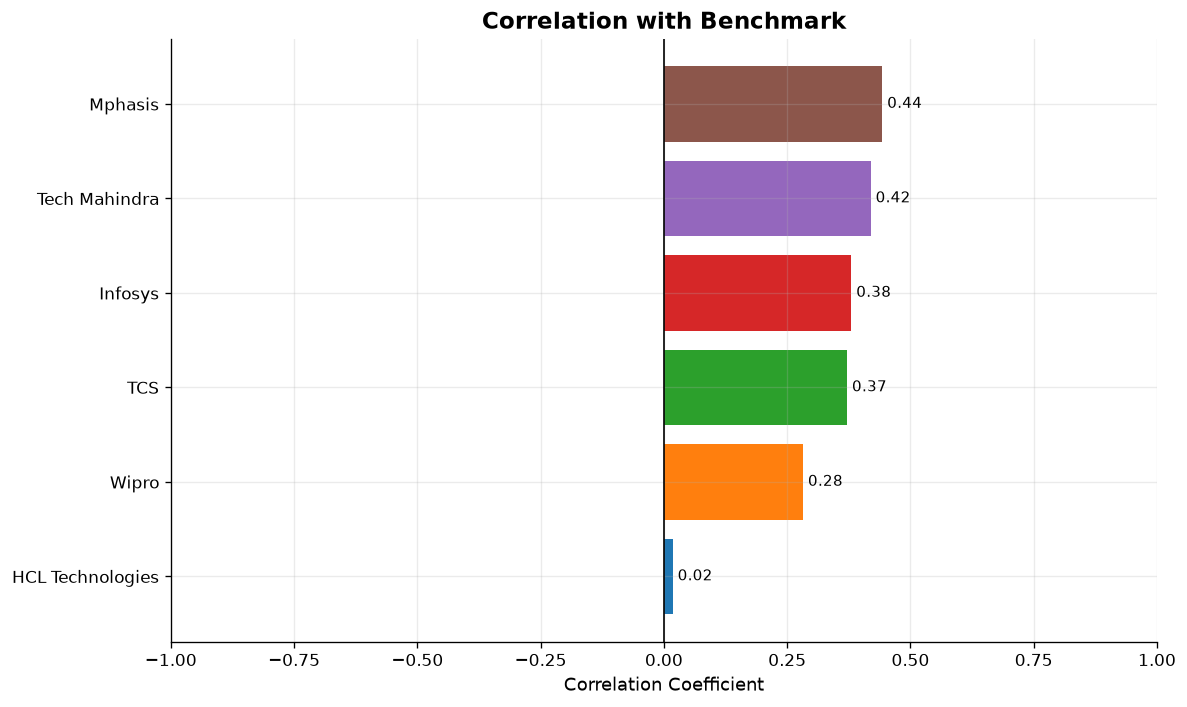

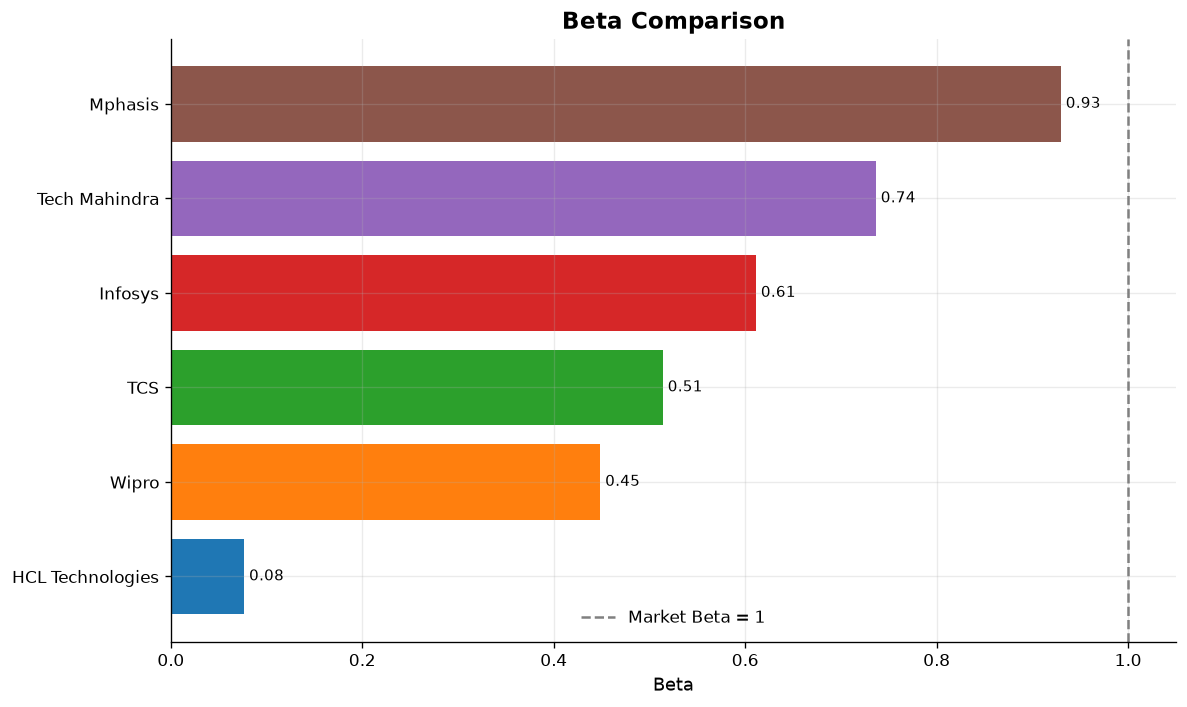

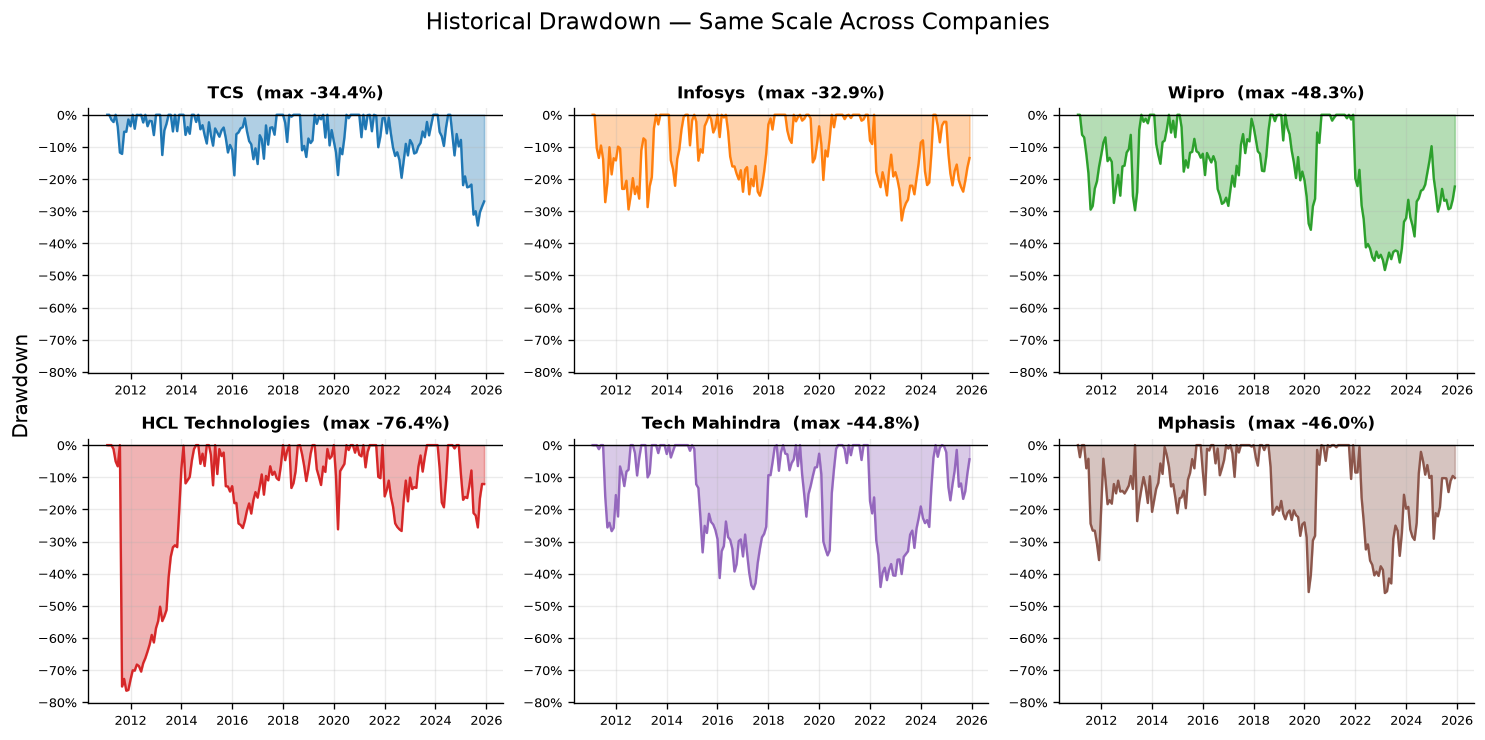

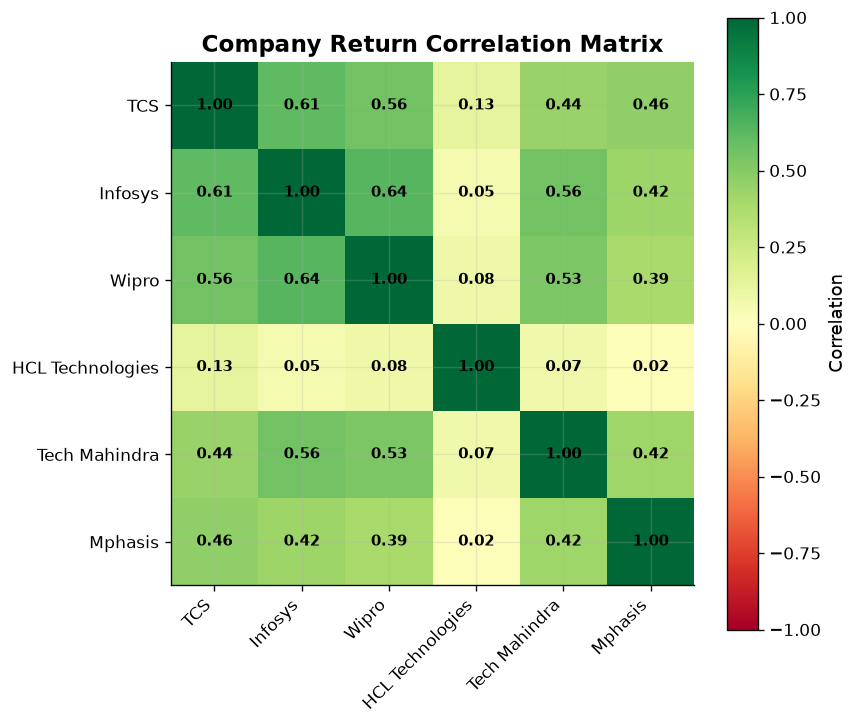

['D:\\industry-risk-return-analysis\\figures\\01_price_history.png',
 'D:\\industry-risk-return-analysis\\figures\\02_growth_of_one_rupee.png',
 'D:\\industry-risk-return-analysis\\figures\\03_cagr_comparison.png',
 'D:\\industry-risk-return-analysis\\figures\\04_volatility_comparison.png',
 'D:\\industry-risk-return-analysis\\figures\\05_drawdown_comparison.png',
 'D:\\industry-risk-return-analysis\\figures\\06_risk_return_scatter.png',
 'D:\\industry-risk-return-analysis\\figures\\07_correlation_comparison.png',
 'D:\\industry-risk-return-analysis\\figures\\08_beta_comparison.png',
 'D:\\industry-risk-return-analysis\\figures\\09_drawdown_curves.png',
 'D:\\industry-risk-return-analysis\\figures\\10_correlation_heatmap.png']

In [26]:
price_with_benchmark = price_data  # includes the benchmark, for charts 1 & 2
fig_paths = viz.generate_all_visualizations(price_with_benchmark, company_returns, comparison_df, cfg.FIGURES_DIR)
fig_paths

## 18. Company Profiles

Generated only from the calculated values above — nothing invented.

In [27]:
profiles = comp.generate_all_profiles(comparison_df)
for name, text in profiles.items():
    print(text)
    print("\n" + "-" * 40 + "\n")

TCS

Return Profile
  - CAGR: 14.53%
  - Cumulative Return: 656.39%
  - Average Monthly Return: 1.34%

Risk Profile
  - Annualized Volatility: 22.33%
  - Maximum Drawdown: -34.45%
  - Downside Deviation: 17.92%

Risk-Adjusted Profile
  - Sharpe: 0.42
  - Sortino: 0.49
  - Calmar: 0.42

Market Relationship
  - Beta: 0.51
  - Correlation: 0.37

----------------------------------------

Infosys

Return Profile
  - CAGR: 12.73%
  - Cumulative Return: 497.65%
  - Average Monthly Return: 1.28%

Risk Profile
  - Annualized Volatility: 25.95%
  - Maximum Drawdown: -32.88%
  - Downside Deviation: 25.13%

Risk-Adjusted Profile
  - Sharpe: 0.33
  - Sortino: 0.33
  - Calmar: 0.39

Market Relationship
  - Beta: 0.61
  - Correlation: 0.38

----------------------------------------

Wipro

Return Profile
  - CAGR: 9.29%
  - Cumulative Return: 276.38%
  - Average Monthly Return: 1.01%

Risk Profile
  - Annualized Volatility: 25.66%
  - Maximum Drawdown: -48.31%
  - Downside Deviation: 23.02%

Risk-Adju

## 19. Key Findings

Generated from `leaders` (Section 16) — fill in / re-run after a real
data pull. Example of how to read it programmatically:


In [28]:
def describe_leader(metric_name):
    row = leaders.loc[leaders["Metric"] == metric_name].iloc[0]
    return f"{metric_name}: {row['Historical Leader']} ({row['Note']}, value = {row['Value']:.4f})"

for metric in ["CAGR", "Annualized Volatility", "Max Drawdown", "Sharpe Ratio", "Beta (Regression)"]:
    print(describe_leader(metric))

print("\nThese are historical observations over one specific sample period and are not a forecast.")

CAGR: HCL Technologies (highest, value = 0.2177)
Annualized Volatility: TCS (lowest, value = 0.2233)
Max Drawdown: Infosys (highest, value = -0.3288)
Sharpe Ratio: Tech Mahindra (highest, value = 0.5300)
Beta (Regression): Mphasis (most extreme, value = 0.9297)

These are historical observations over one specific sample period and are not a forecast.


## 20. Limitations

- **Risk-free rate.** Sharpe/Sortino depend on `RISK_FREE_RATE` in `config.py` — an unset or poorly chosen rate changes the results.
- **Dividend adjustment unverifiable.** `auto_adjust=True` corrects for splits/bonus issues, but whether dividend reinvestment is included cannot be confirmed from yfinance data alone.
- **Descriptive, not predictive.** All metrics characterize the sample period only.
- **No transaction costs, taxes, or investment strategy** are modeled.
- **Corporate-action flags require manual review** — large-move flags are not automatically corporate actions vs. genuine market moves.
- **Same industry ≠ same behavior** — the correlation heatmap (chart 10) often shows this directly.


## 21. Conclusion

This notebook generalizes the original Reliance-only analysis into a
reusable peer-comparison framework: change `COMPANIES` in `src/config.py`
and rerun to analyze any industry, using the same rigorous
return → risk → market-relationship progression as the original project.

$$\boxed{\text{Performance (Return, CAGR)} \rightarrow \text{Risk (Volatility, Drawdown)} \rightarrow \text{Market Relationship (Beta, Correlation)}}$$

Natural extensions: rolling beta/volatility, sector-level aggregation,
and a defended risk-free-rate assumption for Sharpe/Sortino.

> **Disclaimer:** This project is an educational, historical, quantitative
> analysis. It does not constitute investment advice or a recommendation
> to buy or sell any security.
